# Q4. In which brain area are pairwise spike-train interactions strongest at the 100 ms timescale?

**Measure: the spike time tiling coefficient (STTC)** with Δt = 100 ms, for every pair of units recorded in the same area (Cutts & Eglen, 2014). It asks how often spikes of one unit fall within ±100 ms of spikes of the other, compared with what chance alone would give:
- STTC = 0: independent trains.
- STTC = 1: every spike has a partner.
- Negative values: the units avoid each other.

STTC is less sensitive to firing rate than the correlation of spike counts. That matters here because the areas differ in rate (Q1). It still rises somewhat with rate in areas 2 and 3 (section 6).

**Summary per area.** The number of pairs grows with the **square** of the number of units: from 10 pairs (5 units) to 2346 pairs (69 units).
A pooled mean over all pairs would therefore be dominated by a few mice. So the pairs are first averaged within each mouse and area, and the mean over the 18 mice is reported, with a bootstrap 95% CI over mice.
A linear mixed model fitted on all pairs, with random area effects per mouse, is the formal test.

**Robustness checks:**
- shifted-train chance level;
- leaving out possible duplicate units (STTC > 0.5);
- only units ≥ 1 Hz;
- the median pair instead of the mean;
- pooled pairs;
- spike-count correlations.

The code lives in `c2p/q04_pairwise.py` (STTC, count correlations) and `c2p/stats.py`.

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from c2p import AREAS, AREA_COLORS, RESULTS_DIR, Recording
from c2p import q04_pairwise as q4
from c2p.stats import area_bootstrap, lmm_pairwise, per_mouse_tests

pairs = q4.compute()          # cached; q4.compute(force=True) recomputes (~3 min)
print(f"{len(pairs):,} pairs from {pairs.mouse.nunique()} mice")
pairs.groupby(["mouse", "area"]).size().unstack().T

25,299 pairs from 18 mice


mouse,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
area,,,,,,,,,,,,,,,,,,
1,1711,780,1081,561,1711,528,741,528,1326,253,120,171,2346,153,91,1540,276,91
2,231,190,325,15,1596,276,406,496,496,10,703,66,406,45,528,666,946,231
3,21,171,66,136,78,45,300,300,1176,78,171,55,120,120,105,21,630,66


## 1. What STTC measures: two example pairs

The example shows 8 s of two pairs from the same area, one with high STTC and one near 0. The shaded band around every spike of the lower unit is its ±100 ms "tile".
A spike of the upper unit that falls inside a tile (red) counts as a co-occurrence. STTC compares that fraction with the fraction of time the tiles cover.

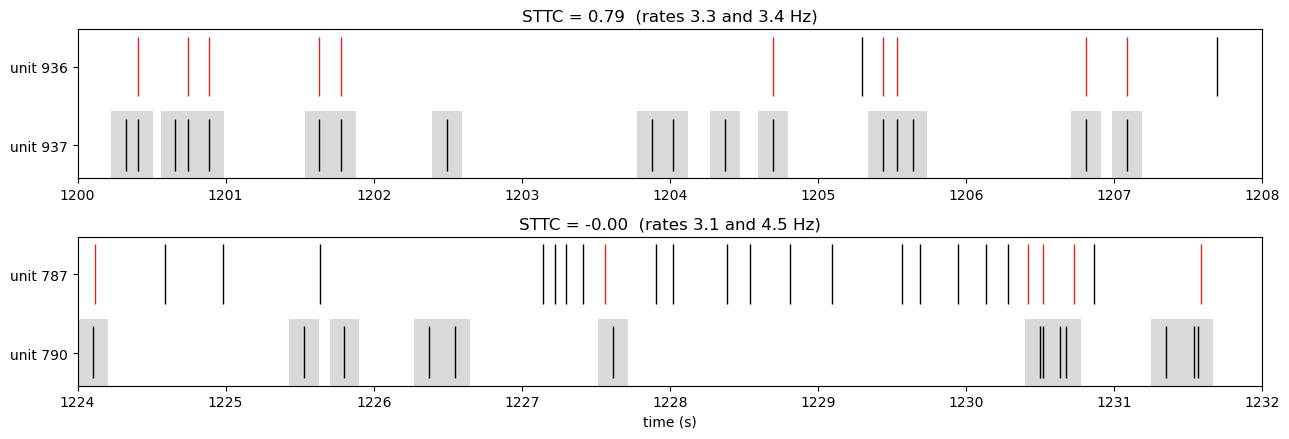

In [2]:
MOUSE, AREA = 1, 2
rec = Recording.load(MOUSE)
p = pairs[(pairs.mouse == MOUSE) & (pairs.area == AREA)]
p = p[(p.rate_a > 2) & (p.rate_b > 2) & (p.rate_a < 8) & (p.rate_b < 8)]
examples = [p.sort_values("sttc").iloc[-1], p.iloc[(p.sttc - 0).abs().argsort().iloc[0]]]
def busy_window(a, b, length=8.0, start=1200.0):
    # first window after `start` in which both units fire at least 10 spikes
    for t0 in np.arange(start, rec.duration_s - length, length):
        if min(((x > t0) & (x < t0 + length)).sum() for x in (a, b)) >= 10:
            return t0, t0 + length
    return start, start + length

fig, axs = plt.subplots(2, 1, figsize=(13, 4.5))
for ax, r in zip(axs, examples):
    a, b = rec.spike_times(r.unit_a), rec.spike_times(r.unit_b)
    t0, t1 = busy_window(a, b)
    a, b = a[(a > t0) & (a < t1)], b[(b > t0) & (b < t1)]
    for s in b:
        ax.axvspan(s - q4.DT, s + q4.DT, ymin=0, ymax=0.45, color="0.85", lw=0)
    near = np.array([np.any(np.abs(b - s) <= q4.DT) for s in a], dtype=bool)
    ax.vlines(a[near], 0.55, 0.95, color="tab:red", lw=1)
    ax.vlines(a[~near], 0.55, 0.95, color="k", lw=1)
    ax.vlines(b, 0.05, 0.4, color="k", lw=1)
    ax.set(yticks=[0.22, 0.75], yticklabels=[f"unit {r.unit_b:.0f}", f"unit {r.unit_a:.0f}"], ylim=(0, 1),
           title=f"STTC = {r.sttc:.2f}  (rates {r.rate_a:.1f} and {r.rate_b:.1f} Hz)")
    ax.set_xlim(t0, t1)
axs[1].set_xlabel("time (s)")
fig.tight_layout()

## 2. STTC of all pairs, against chance

For the chance level, each pair was recomputed after shifting one train in time by a random amount (at least 10 s). This keeps each train intact but destroys their timing relation.
The real values are clearly shifted to the right of chance in every area, so the STTC reflects genuine co-firing.

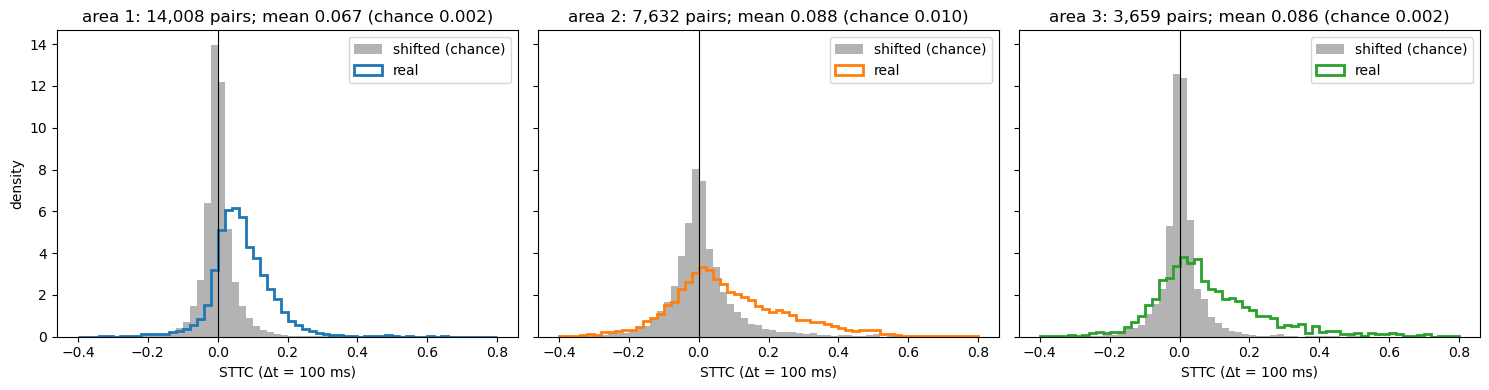

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
bins = np.linspace(-0.4, 0.8, 61)
for ax, a in zip(axs, AREAS):
    g = pairs[pairs.area == a]
    ax.hist(g.sttc_shifted, bins, color="0.7", density=True, label="shifted (chance)")
    ax.hist(g.sttc, bins, histtype="step", lw=2, color=AREA_COLORS[a], density=True, label="real")
    ax.axvline(0, color="k", lw=0.8)
    ax.set(title=f"area {a}: {len(g):,} pairs; mean {g.sttc.mean():.3f} (chance {g.sttc_shifted.mean():.3f})",
           xlabel="STTC (Δt = 100 ms)")
    ax.legend()
axs[0].set_ylabel("density")
fig.tight_layout()

## 3. Mouse by mouse

Each line is one mouse's mean STTC over its pairs in each area. The right panel shows that the per-mouse value is noisier when there are few pairs.
That's why the mixed model weighs them sensibly, rather than pooling all pairs.

Friedman p = 0.223


,mice where x > y,n mice,wilcoxon p,wilcoxon p (Bonferroni)
pair,,,,
area 1 vs area 2,6,18,0.0139,0.0416
area 1 vs area 3,9,18,0.6397,1.0000
area 2 vs area 3,12,18,0.0737,0.2211


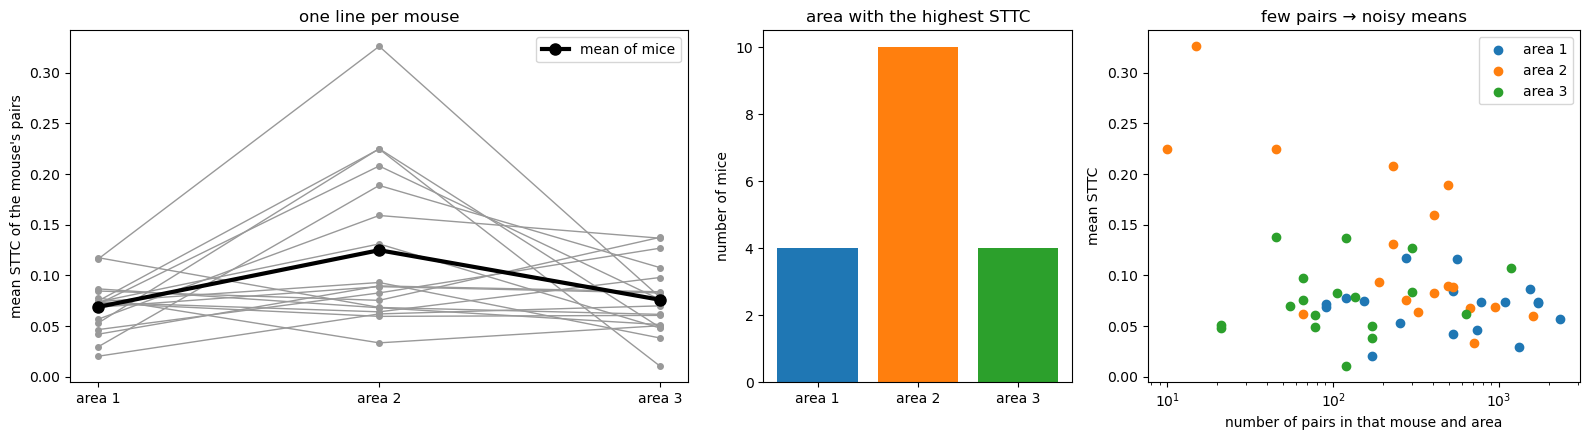

In [4]:
per_mouse, friedman, wilc = per_mouse_tests(pairs, "sttc")
n_pairs = pairs.groupby(["mouse", "area"]).size().unstack()
highest = per_mouse.idxmax(axis=1).value_counts().reindex(AREAS, fill_value=0)

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw=dict(width_ratios=[2, 1, 1.4]))
for m, row in per_mouse.iterrows():
    axs[0].plot(AREAS, row.values, "-o", color="0.6", ms=4, lw=1)
axs[0].plot(AREAS, per_mouse.mean().values, "-o", color="k", lw=3, ms=8, label="mean of mice")
axs[0].set(xticks=AREAS, xticklabels=[f"area {a}" for a in AREAS], ylabel="mean STTC of the mouse's pairs",
           title="one line per mouse"); axs[0].legend()
axs[1].bar([f"area {a}" for a in AREAS], highest.values, color=[AREA_COLORS[a] for a in AREAS])
axs[1].set(ylabel="number of mice", title="area with the highest STTC")
for a in AREAS:
    axs[2].scatter(n_pairs[a], per_mouse[a], color=AREA_COLORS[a], label=f"area {a}")
axs[2].set(xscale="log", xlabel="number of pairs in that mouse and area", ylabel="mean STTC", title="few pairs → noisy means")
axs[2].legend()
fig.tight_layout()
print("Friedman p =", round(friedman.pvalue, 3))
wilc.round(4)

## 4. Mean and 95% CI

The **main** estimate is one value per mouse and area (the mean of its pairs), averaged over mice, with a bootstrap over mice.
For comparison, the second table pools all pairs (a hierarchical bootstrap over mice, then pairs). It gives large weight to the few mice with hundreds or thousands of pairs.

In [5]:
mouse_level = pairs.groupby(["mouse", "area"]).sttc.mean().rename("sttc").reset_index()
t_main, boot_main = area_bootstrap(mouse_level, "sttc")
t_pool, _ = area_bootstrap(pairs, "sttc", n_boot=2000)
print("Main: mice weighted equally"); display(t_main.round(4))
print("Pooled pairs"); display(t_pool.round(4))

Main: mice weighted equally


,estimate,ci_low,ci_high,p (diff = 0)
area 1,0.0690,0.0576,0.0804,NaN
area 2,0.1249,0.0919,0.1625,NaN
area 3,0.0760,0.0605,0.0920,NaN
area 1 − area 2,-0.0559,-0.0926,-0.0213,0.0008
area 1 − area 3,-0.0070,-0.0286,0.0140,0.5186
area 2 − area 3,0.0489,0.0110,0.0909,0.0086


Pooled pairs


,estimate,ci_low,ci_high,p (diff = 0)
area 1,0.0674,0.0566,0.0778,NaN
area 2,0.0880,0.0693,0.1163,NaN
area 3,0.0856,0.0620,0.1022,NaN
area 1 − area 2,-0.0205,-0.0563,0.0059,0.139
area 1 − area 3,-0.0181,-0.0422,0.0135,0.275
area 2 − area 3,0.0024,-0.0155,0.0294,0.711


## 5. Mixed model on all pairs

The model is `STTC ~ area + (area | mouse)`. It uses every pair, but it accounts for pairs being nested in mice, and for the area difference itself varying from mouse to mouse.

In [6]:
lmm = lmm_pairwise(pairs, "sttc")
lmm.round(4)

,coef,ci_low,ci_high,p,converged,p (Bonferroni)
contrast,,,,,,
area 1 − area 2,-0.0524,-0.0875,-0.0172,0.0035,True,0.0106
area 1 − area 3,-0.0075,-0.0300,0.0149,0.5094,True,1.0000
area 2 − area 3,0.0448,0.0056,0.0841,0.0252,True,0.0757


## 6. Robustness

- **No pairs > 0.5:** very high STTC can come from one neuron that was split into two clusters by spike sorting.
- **Rates ≥ 1 Hz:** STTC from sparse trains is noisy.
- **Median pair:** the median instead of the mean per mouse.
- **≥ 10 units:** drops mouse–area combinations with fewer than 10 units (< 45 pairs), whose means are noisy (section 3). The per-mouse count in this row covers only the mice that have all three areas left.
- **Count correlation:** Pearson correlation of 100-ms spike counts, the other common measure. It grows with firing rate, so it partly reflects Q1 rather than interaction strength.

In [7]:
def summary(df, value="sttc", agg="mean"):
    pm = df.groupby(["mouse", "area"])[value].agg(agg).unstack()
    lm = lmm_pairwise(df, value) if agg == "mean" else None
    return {**{f"area {a}": pm[a].mean() for a in AREAS},
            "highest (mean of mice)": f"area {pm.mean().idxmax()}",
            "highest in n mice": dict(pm.idxmax(axis=1).value_counts().sort_index()),
            "LMM p 2 vs 1": None if lm is None else lm.loc["area 1 − area 2", "p"],
            "LMM p 2 vs 3": None if lm is None else lm.loc["area 2 − area 3", "p"]}

rows = {"main (STTC, mean of pairs)": summary(pairs),
        "no pairs with STTC > 0.5": summary(pairs[pairs.sttc <= 0.5]),
        "both units ≥ 1 Hz": summary(pairs[(pairs.rate_a >= 1) & (pairs.rate_b >= 1)]),
        "median pair": summary(pairs, agg="median"),
        "only mouse-areas with ≥ 10 units": summary(pairs.groupby(["mouse", "area"]).filter(lambda g: len(g) >= 45)),
        "count correlation (100-ms bins)": summary(pairs, "count_corr")}
robust = pd.DataFrame(rows).T
robust

,area 1,area 2,area 3,highest (mean of mice),highest in n mice,LMM p 2 vs 1,LMM p 2 vs 3
"main (STTC, mean of pairs)",0.069007,0.124911,0.076029,area 2,"{1: 4, 2: 10, 3: 4}",0.003521,0.02524
no pairs with STTC > 0.5,0.066866,0.109268,0.063662,area 2,"{1: 4, 2: 11, 3: 3}",0.016932,0.016069
both units ≥ 1 Hz,0.071249,0.141454,0.081915,area 2,"{1: 4, 2: 9, 3: 5}",0.002025,0.013472
median pair,0.06311,0.107658,0.051155,area 2,"{1: 6, 2: 8, 3: 4}",None,None
only mouse-areas with ≥ 10 units,0.069007,0.106093,0.079298,area 2,"{1: 6, 2: 8, 3: 4}",0.035739,0.129729
count correlation (100-ms bins),0.044954,0.082046,0.069947,area 2,"{1: 2, 2: 7, 3: 9}",0.004081,0.53451


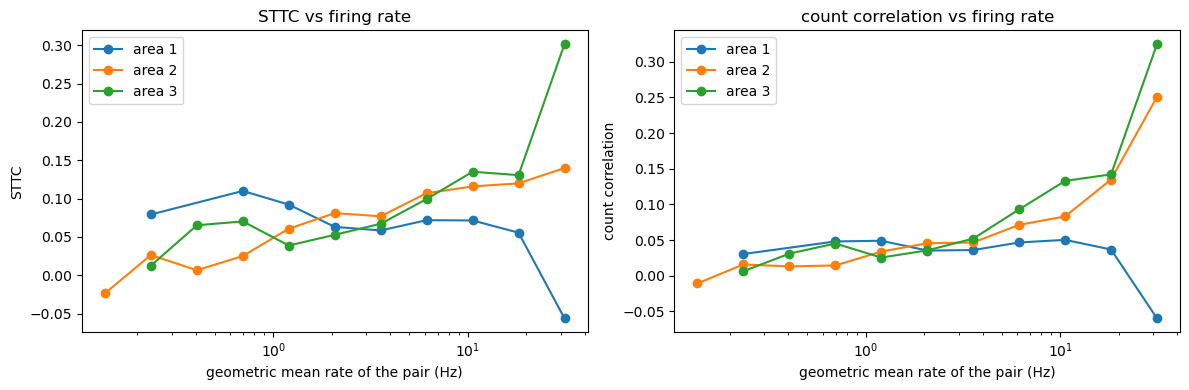

In [8]:
pairs["gm_rate"] = np.sqrt(pairs.rate_a * pairs.rate_b)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
bins = np.logspace(-1, 1.6, 12)
for a in AREAS:
    g = pairs[pairs.area == a]
    for ax, col in zip(axs, ["sttc", "count_corr"]):
        m = g.groupby(pd.cut(g.gm_rate, bins), observed=True)[col].mean()
        ax.plot([iv.mid for iv in m.index], m.values, "-o", color=AREA_COLORS[a], label=f"area {a}")
for ax, t in zip(axs, ["STTC", "count correlation"]):
    ax.set(xscale="log", xlabel="geometric mean rate of the pair (Hz)", ylabel=t, title=f"{t} vs firing rate")
    ax.legend()
fig.tight_layout()

## 7. Answer for the questionnaire

In [9]:
answer = t_main.iloc[:3, :3].copy()
answer.columns = ["Mean", "CI low", "CI high"]
answer["95% C.I."] = answer.apply(lambda r: f"[{r['CI low']:.3f}, {r['CI high']:.3f}]", axis=1)
answer["Units"] = "STTC (Δt = 100 ms)"
answer = answer[["Mean", "95% C.I.", "Units"]].round(3)
answer.to_csv(RESULTS_DIR / "q04_answer.csv")
answer

,Mean,95% C.I.,Units
area 1,0.069,"[0.058, 0.080]",STTC (Δt = 100 ms)
area 2,0.125,"[0.092, 0.162]",STTC (Δt = 100 ms)
area 3,0.076,"[0.061, 0.092]",STTC (Δt = 100 ms)


In [10]:
from c2p.questionnaire import fill_pdf, record_answer

m = t_main.estimate
w = wilc["wilcoxon p (Bonferroni)"]
lm = lmm["p (Bonferroni)"]
explanation = (
    f"For every pair of units recorded in the same area ({len(pairs):,} pairs) I computed the spike time tiling "
    f"coefficient (STTC) with dt = 100 ms, which measures how often the spikes of two units fall within 100 ms of each "
    f"other beyond chance and is less sensitive to firing rate than count correlations. Circularly shifting one spike "
    f"train brought STTC to about 0, confirming that the values reflect genuine co-firing. Because the number of pairs "
    f"grows with the square of the number of units, a pooled mean would be dominated by a few mice, so I averaged pairs "
    f"within each mouse and area and report the mean over the 18 mice with a bootstrap CI. Area 2 had the highest mean "
    f"STTC ({m['area 2']:.3f} vs {m['area 1']:.3f} in area 1 and {m['area 3']:.3f} in area 3) and exceeded area 1 "
    f"(paired Wilcoxon p = {w['area 1 vs area 2']:.3f}), but not area 3: it was higher in only "
    f"{int((per_mouse[2] > per_mouse[3]).sum())} of 18 mice (p = {w['area 2 vs area 3']:.2f}), a linear mixed model on "
    f"all pairs with random area effects per mouse gave p = {lm['area 2 − area 3']:.3f}, and pooling all pairs did not "
    f"separate the areas. Pairwise p-values are Bonferroni-corrected for the three comparisons. Because no area was "
    f"reliably above both others, I answer not enough data / no differences."
)
print(len(explanation.split()), "words")
record_answer(4, choice=3,                                   # 3 = not enough data / no differences
              rows=[(f"{r.Mean:.3f}", r["95% C.I."], "dimensionless") for _, r in answer.iterrows()],
              explanation=explanation)
from c2p.questionnaire import record_meta
record_meta(4, confidence=4, consensus=3)
print(fill_pdf())
print(explanation)


208 words


/home/dariosannino/con2phys/docs/questionnaire_filled.pdf
For every pair of units recorded in the same area (25,299 pairs) I computed the spike time tiling coefficient (STTC) with dt = 100 ms, which measures how often the spikes of two units fall within 100 ms of each other beyond chance and is less sensitive to firing rate than count correlations. Circularly shifting one spike train brought STTC to about 0, confirming that the values reflect genuine co-firing. Because the number of pairs grows with the square of the number of units, a pooled mean would be dominated by a few mice, so I averaged pairs within each mouse and area and report the mean over the 18 mice with a bootstrap CI. Area 2 had the highest mean STTC (0.125 vs 0.069 in area 1 and 0.076 in area 3) and exceeded area 1 (paired Wilcoxon p = 0.042), but not area 3: it was higher in only 12 of 18 mice (p = 0.22), a linear mixed model on all pairs with random area effects per mouse gave p = 0.076, and pooling all pairs did not

## Conclusion

**Not enough data / no differences.** Area 2 has the highest mean STTC (about 0.125 vs 0.07 and 0.08), and it is reliably above area 1.
It is **not** reliably above area 3 once the three pairwise tests are corrected for multiple comparisons:
- higher in only 12 of 18 mice (corrected Wilcoxon p ≈ 0.22);
- the mixed model's corrected p is ≈ 0.08;
- pooling all pairs doesn't separate the areas.

Because no area reliably beats both others, the answer is "no differences". The numbers above still show area 2 as the most likely candidate.
